# Данные Даши: состояние = тяжесть обвинения

Отдельный эксперимент Этапа 1. Журнал строится не по таблице этапа 0, а по таблице Даши
`individual_custody_timeline_rfm.csv` (18 668 заключений). Состояние процесса — **степень тяжести обвинения**
(F1, F2, F3, …, M1, M2), а не тип преступления.

**Проблема исходной колонки.** В таблице Даши `c_charge_degree` у 99% людей одна и та же во всех заключениях: это
обвинение из дела COMPAS, скопированное в каждую строку. Граф по ней состоит только из петель X → X (шаг 3).
Поэтому основной вариант берёт тяжесть **для каждого заключения отдельно** из `compas.db`: самое тяжёлое обвинение
ареста, с которого началось заключение (правила в `dasha_severity.py`, те же, что в `stage1/build_episode_charges.py`).
Колонка Даши как есть считается рядом для сравнения.

**Состояния (7).** `F1`, `F2`, `F3`, `F_other` (F5, F6, F7 — 47 заключений), `M1`, `M2` (M2 и MO3), `Unknown`
(обвинение не найдено или редкий код: CO3, NI0, 0).

**Журнал.** Одно событие на заключение, время = вход в заключение. Кейс — человек (`person_id` из compas.db, если
нашёлся, иначе имя). Заключения без даты входа выброшены. Состояния END нет: последнее заключение каждого человека
цензурировано (наблюдение до 2016-04-19).

**Как запустить.** Окружение `D:\Git\diploma\.venv`, открыть ноутбук из этой папки, *Run All*. Входы: таблица Даши
(`data\individual_custody_timeline_rfm.csv` рядом с ноутбуком или `D:\Git\diploma\recurrent_event\data\…`) и
`jupyter lab\stage0 - data\compas.db`. Результаты пишутся в `out\`.

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
import pm4py
import dasha_severity as S

HERE = Path.cwd()
ROOT = HERE.parent.parent                       # jupyter lab (на компьютере) или корень репозитория
first = lambda c: next((p for p in c if p.exists()), c[0])
DASHA = first([HERE / "data" / "individual_custody_timeline_rfm.csv",
               Path(r"D:\Git\diploma\recurrent_event\data\individual_custody_timeline_rfm.csv")])
DB = first([ROOT / "stage0 - data" / "compas.db", ROOT / "stage0-data" / "compas.db"])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

MODELS = ["HM_0.5", "HM_0.9", "HM_0.95", "IM_0.0", "IM_0.2", "IM_0.5"]
EVAL_CASES = 2000           # людей в выборках train/test для fitness/precision
ALIGN_CASES = 2000          # precision через выравнивания для HM 0.9 (0 — не считать)
print("pm4py", pm4py.__version__)
print("таблица Даши:", DASHA, DASHA.exists())
print("compas.db:", DB, DB.exists())


def show(path, max_px=1400):
    from io import BytesIO
    from PIL import Image as PILImage
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg"))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9
таблица Даши: /tmp/claude-0/w/jl/stage1/dasha_severity/data/individual_custody_timeline_rfm.csv True
compas.db: /tmp/claude-0/w/jl/stage0 - data/compas.db True


## Шаг 1. Тяжесть каждого заключения

Для каждой строки таблицы Даши ищется человек в `compas.db` и обвинения ареста, с которого началось заключение;
из них берётся самое тяжёлое. Расчёт занимает около минуты.

In [2]:
dasha = pd.read_csv(DASHA)
t0 = time.time()
ep = S.episode_degree(dasha, DB)
print(f"готово за {time.time() - t0:.0f} с, заключений {len(ep)}")
print("\nОткуда взято обвинение:")
print(ep["ep_charge_source"].value_counts().to_string())
dated = ep["in_custody"].notna()
same = (ep.loc[dated, "ep_charge_degree"].fillna("-") == ep.loc[dated, "c_charge_degree"].fillna("-")).mean()
print(f"\nТяжесть по заключению совпадает с колонкой Даши в {same:.1%} заключений")
print("Людей, у которых тяжесть в колонке Даши меняется между заключениями:",
      int((ep.groupby("name")["c_charge_degree"].nunique() > 1).sum()), "из", ep["name"].nunique())

готово за 37 с, заключений 18668

Откуда взято обвинение:
ep_charge_source
arrest        15936
none           1682
prior_case      991
offense          59

Тяжесть по заключению совпадает с колонкой Даши в 68.1% заключений
Людей, у которых тяжесть в колонке Даши меняется между заключениями: 77 из 10855


In [3]:
pd.crosstab(ep.loc[dated, "c_charge_degree"].map(S.to_state).rename("колонка Даши"),
            ep.loc[dated, "ep_charge_degree"].map(S.to_state).rename("по заключению")
            ).reindex(index=S.STATE_ORDER, columns=S.STATE_ORDER, fill_value=0)

по заключению,F1,F2,F3,F_other,M1,M2,Unknown
колонка Даши,,,,,,,
F1,219,25,20,1,7,5,17
F2,90,1127,149,1,94,29,53
F3,279,1630,7165,2,681,384,247
F_other,31,55,55,41,14,7,12
M1,41,184,384,2,2874,121,122
M2,20,93,220,0,484,399,154
Unknown,2,0,12,0,4,9,509


## Шаг 2. Журнал событий (два варианта)

In [4]:
LOGS = {"по заключению": S.build_log(ep, "ep_charge_degree"),
        "колонка Даши": S.build_log(ep, "c_charge_degree")}
log = LOGS["по заключению"]
log.to_csv(OUT / "event_log_dasha_severity.csv", index=False)
LOGS["колонка Даши"].to_csv(OUT / "event_log_dasha_column.csv", index=False)
log.head(10)

,case:concept:name,concept:name,time:timestamp,out_custody,ep_row,name,person_id,ep_charge_degree
0,p1,F3,2013-08-13,2013-08-14,12889,miguel hernandez,1,(F3)
1,p1,F3,2014-07-07,2014-07-14,12890,miguel hernandez,1,(F3)
2,p10,M1,2014-03-15,2014-03-18,5606,elizabeth thieme,10,(M1)
3,p100,M1,2013-09-28,2013-10-01,12382,merlita hanson,100,(M1)
4,p1000,F3,2014-11-05,2014-12-30,8245,jeffrey forrest,1000,(F3)
5,p1000,F3,2015-01-16,2015-02-19,8246,jeffrey forrest,1000,(F3)
6,p1000,F3,2016-02-09,NaT,8247,jeffrey forrest,1000,(F3)
7,p10000,M1,2014-05-31,2014-06-02,9689,juan crespo,10000,(M1)
8,p10001,M1,2014-10-24,2014-10-25,15423,sabra mitchell,10001,(M1)
9,p10002,Unknown,2013-01-04,2013-01-05,13622,pancia gerald,10002,NaN


## Шаг 3. Статистика

Доля петель X → X — доля переходов между соседними заключениями человека, в которых тяжесть не меняется.

In [5]:
stats = pd.DataFrame({k: S.log_stats(v) for k, v in LOGS.items()})
stats.to_csv(OUT / "log_stats.csv")
stats

,по заключению,колонка Даши
состояний,7.000,7.0
людей,10406.000,10406.0
событий,18074.000,18074.0
людей с 1 заключением,6193.000,6193.0
переходов,7668.000,7668.0
дуг DFG,42.000,8.0
доля петель X→X,0.662,1.0
вариантов трасс,518.000,58.0
людей с уникальной трассой,313.000,8.0


In [6]:
freq = pd.DataFrame({k: v["concept:name"].value_counts() for k, v in LOGS.items()}).reindex(S.STATE_ORDER).fillna(0).astype(int)
freq.to_csv(OUT / "state_counts.csv")
freq

,по заключению,колонка Даши
concept:name,,
F1,682,294
F2,3114,1543
F3,8005,10388
F_other,47,215
M1,4158,3728
M2,954,1370
Unknown,1114,536


Матрица переходов (по заключению): строка — тяжесть текущего заключения, столбец — следующего, доли по строке.

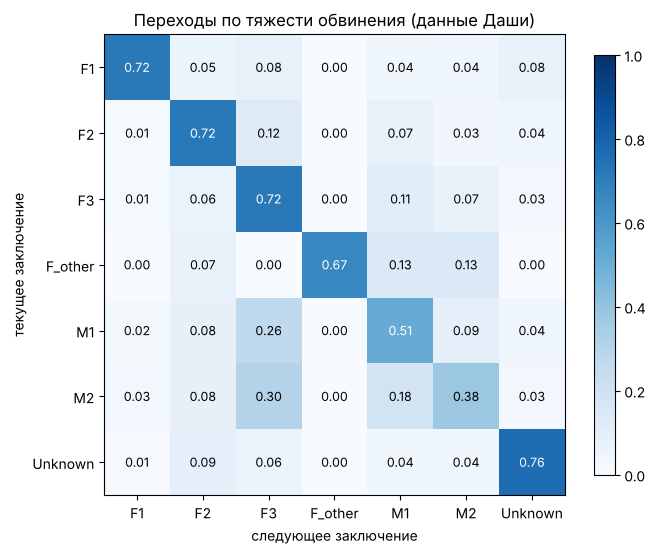

In [7]:
pairs = S.liberty_pairs(log)
cnt = pd.crosstab(pairs["concept:name"], pairs["nxt"]).reindex(index=S.STATE_ORDER, columns=S.STATE_ORDER, fill_value=0)
prob = cnt.div(cnt.sum(axis=1), axis=0).round(3)
cnt.to_csv(OUT / "transition_counts.csv")
prob.to_csv(OUT / "transition_probs.csv")

fig, ax = plt.subplots(figsize=(7, 6))
im_ = ax.imshow(prob.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(prob.columns)), prob.columns)
ax.set_yticks(range(len(prob.index)), prob.index)
for i in range(prob.shape[0]):
    for j in range(prob.shape[1]):
        v = prob.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=9)
ax.set_xlabel("следующее заключение"); ax.set_ylabel("текущее заключение")
ax.set_title("Переходы по тяжести обвинения (данные Даши)")
fig.colorbar(im_, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(FIG / "transition_matrix.png", dpi=120)
plt.show()

## Шаг 4. Граф в PM4Py

### 4.1 DFG по частоте

Состояний всего 7, поэтому DFG рисуется целиком, без фильтра путей.

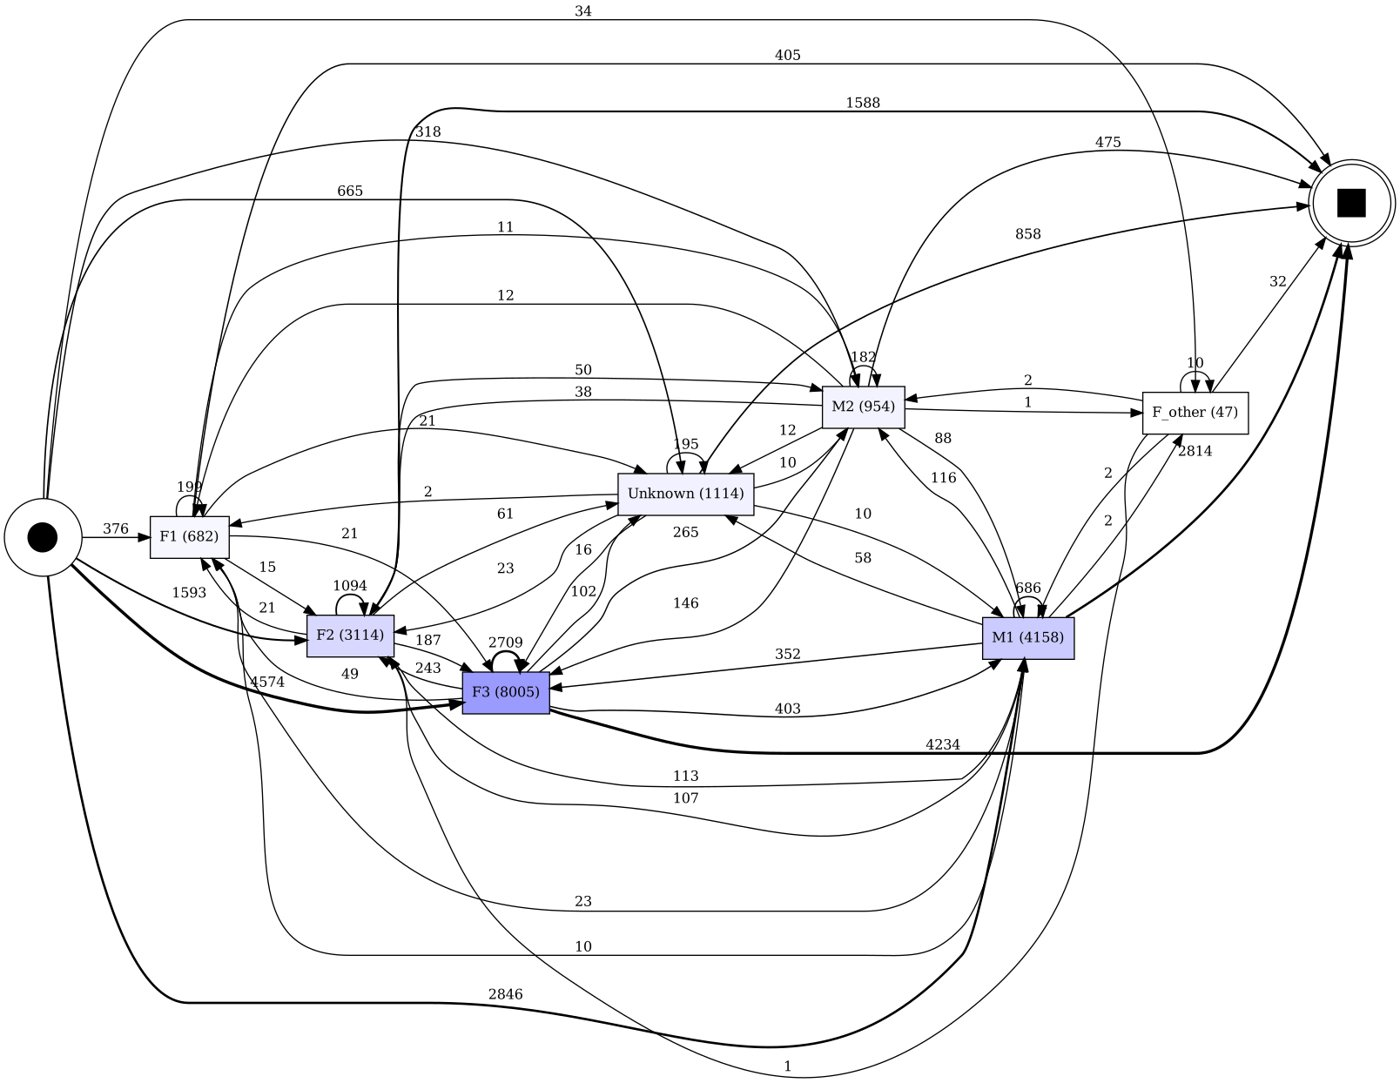

In [8]:
pm_log = pm4py.format_dataframe(log[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                                case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
dfg, sa, ea = pm4py.discover_dfg(pm_log)
pd.Series(dfg).rename("переходов").rename_axis(["из", "в"]).sort_values(ascending=False).to_csv(OUT / "dfg_arcs.csv")
pm4py.save_vis_dfg(dfg, sa, ea, str(FIG / "dfg_frequency.png"))
show(FIG / "dfg_frequency.png")

### 4.2 DFG по времени

Время на дуге — **время на свободе**: от выхода из заключения A до входа в следующее заключение B (медиана, дни).
Отрицательные интервалы (пересечение заключений в данных) приравнены к 0. У Даши `out_custody = 2020-01-01` означает
«ещё в заключении», такие интервалы не считаются.

Медиана времени на свободе по всем переходам: 132 дней


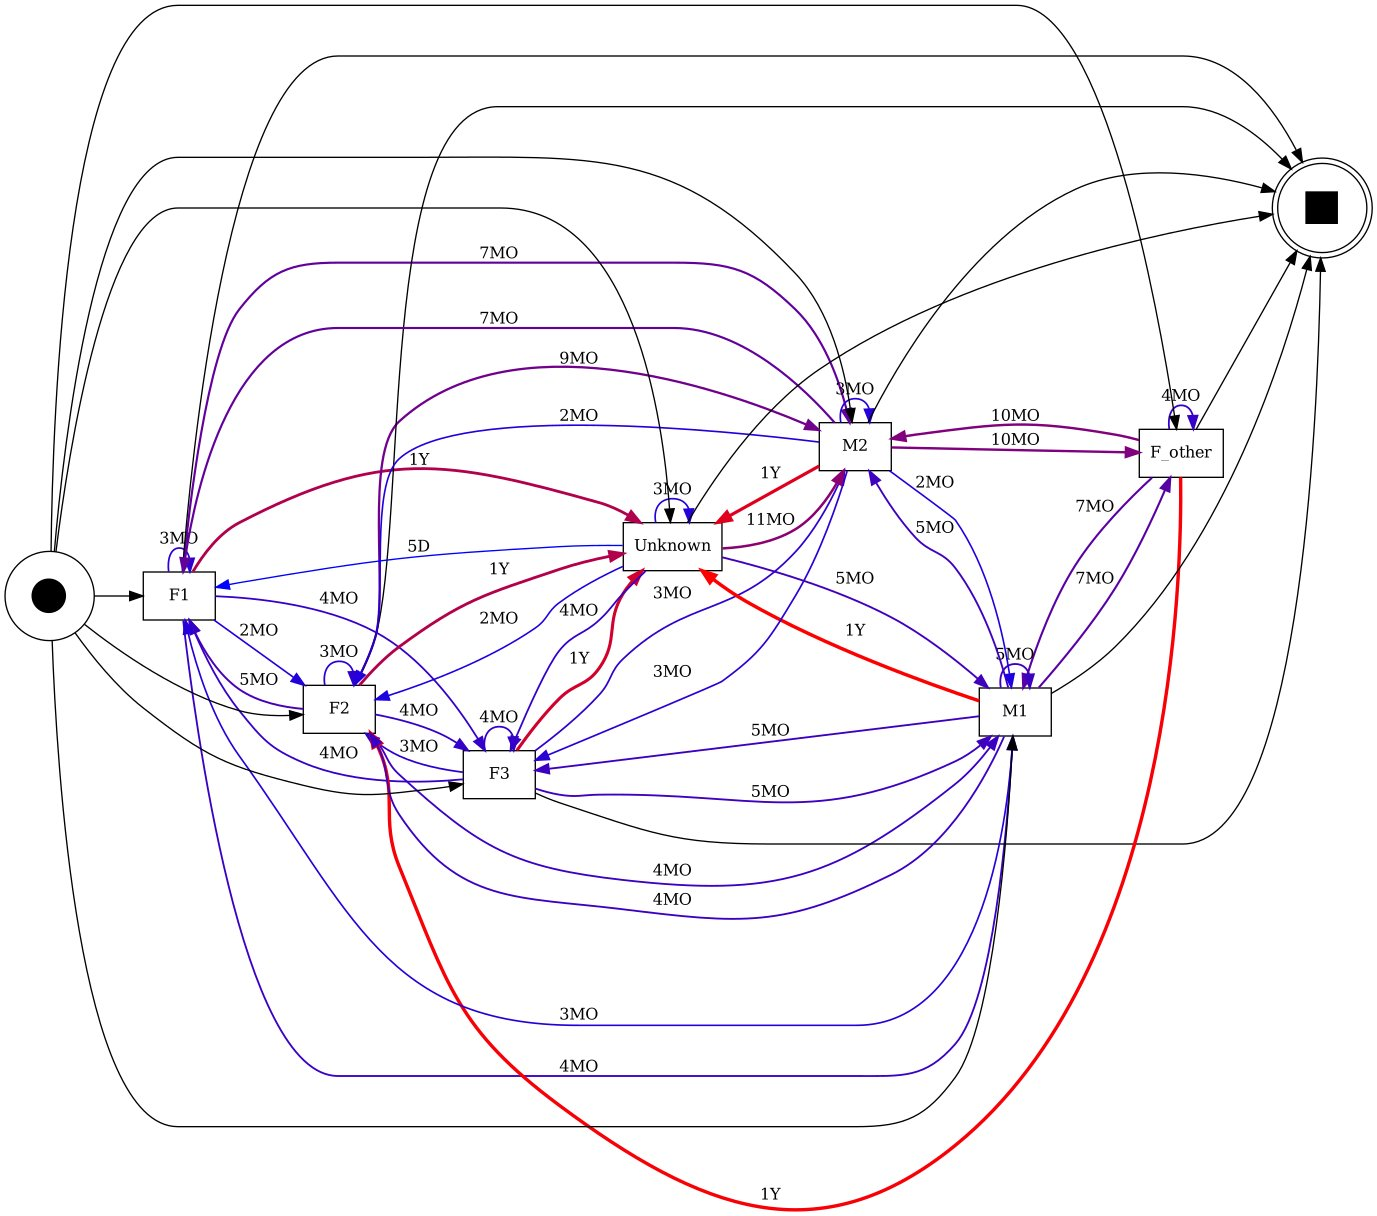

In [9]:
agg = pairs.dropna(subset=["days"]).assign(sec=lambda x: x["days"] * 86400) \
           .groupby(["concept:name", "nxt"])["sec"].agg(["mean", "median", "max", "min", "sum", "std"]).fillna(0)
perf = {k: dict(mean=r["mean"], median=r["median"], max=r["max"], min=r["min"], sum=r["sum"], stdev=r["std"])
        for k, r in agg.iterrows()}
perf = {k: perf.get(k, dict(mean=0, median=0, max=0, min=0, sum=0, stdev=0)) for k in dfg}
pm4py.save_vis_performance_dfg(perf, sa, ea, str(FIG / "dfg_performance.png"), aggregation_measure="median")
times = (agg[["median", "mean"]] / 86400).round(0).rename(columns={"median": "медиана, дни", "mean": "среднее, дни"})
times.to_csv(OUT / "dfg_times_liberty.csv")
print("Медиана времени на свободе по всем переходам:", round(pairs["days"].median()), "дней")
show(FIG / "dfg_performance.png")

### 4.3 Сети Петри: Heuristics Miner и Inductive Miner

Модели строятся на всём журнале «по заключению» для рисунков; качество — в 4.4.

HM 0.9: мест 16, переходов 57


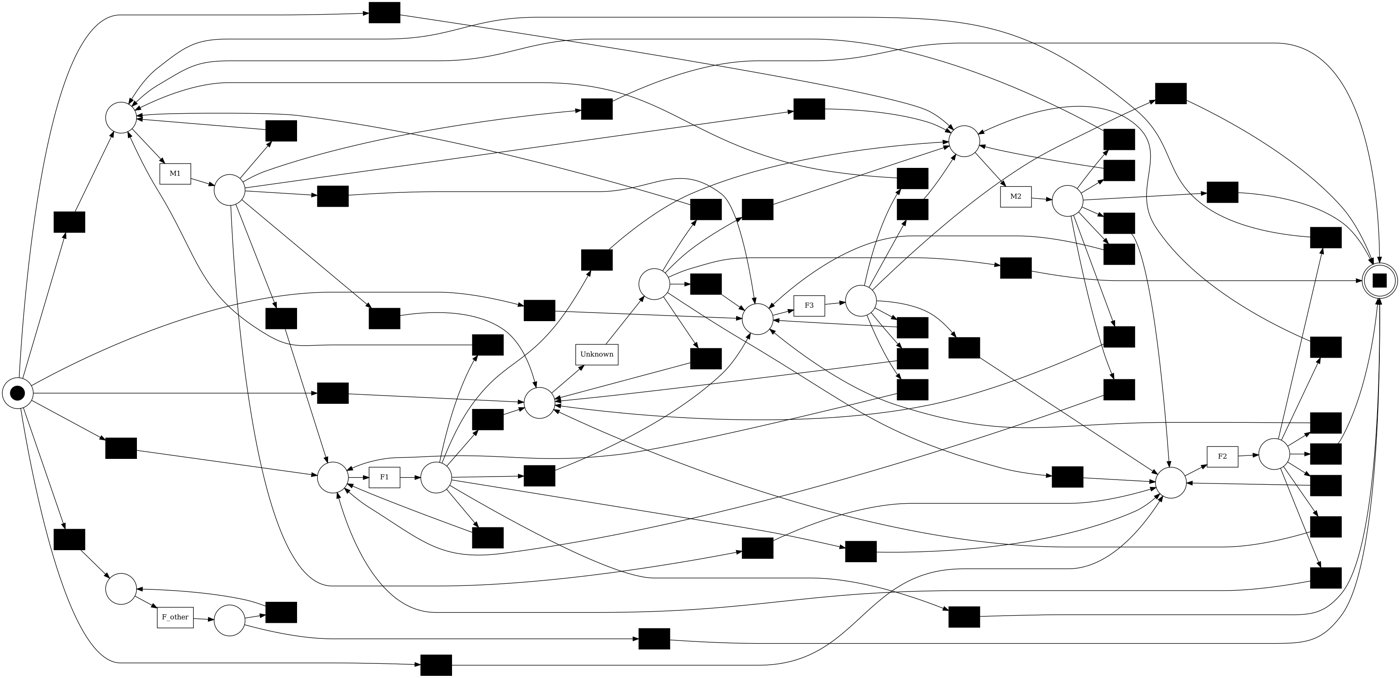

In [10]:
net, im, fm = pm4py.discover_petri_net_heuristics(pm_log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net, im, fm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9: мест {len(net.places)}, переходов {len(net.transitions)}")
show(FIG / "petri_HM_dep0.9.png")

Дерево процесса IM 0.2: +( X( tau, *( 'M2', tau ) ), X( tau, *( 'M1', tau ) ), X( tau, *( 'F_other', tau ), *( 'F3', tau ), *( 'Unknown', tau ), *( 'F1', tau ), *( 'F2', tau ) ) )


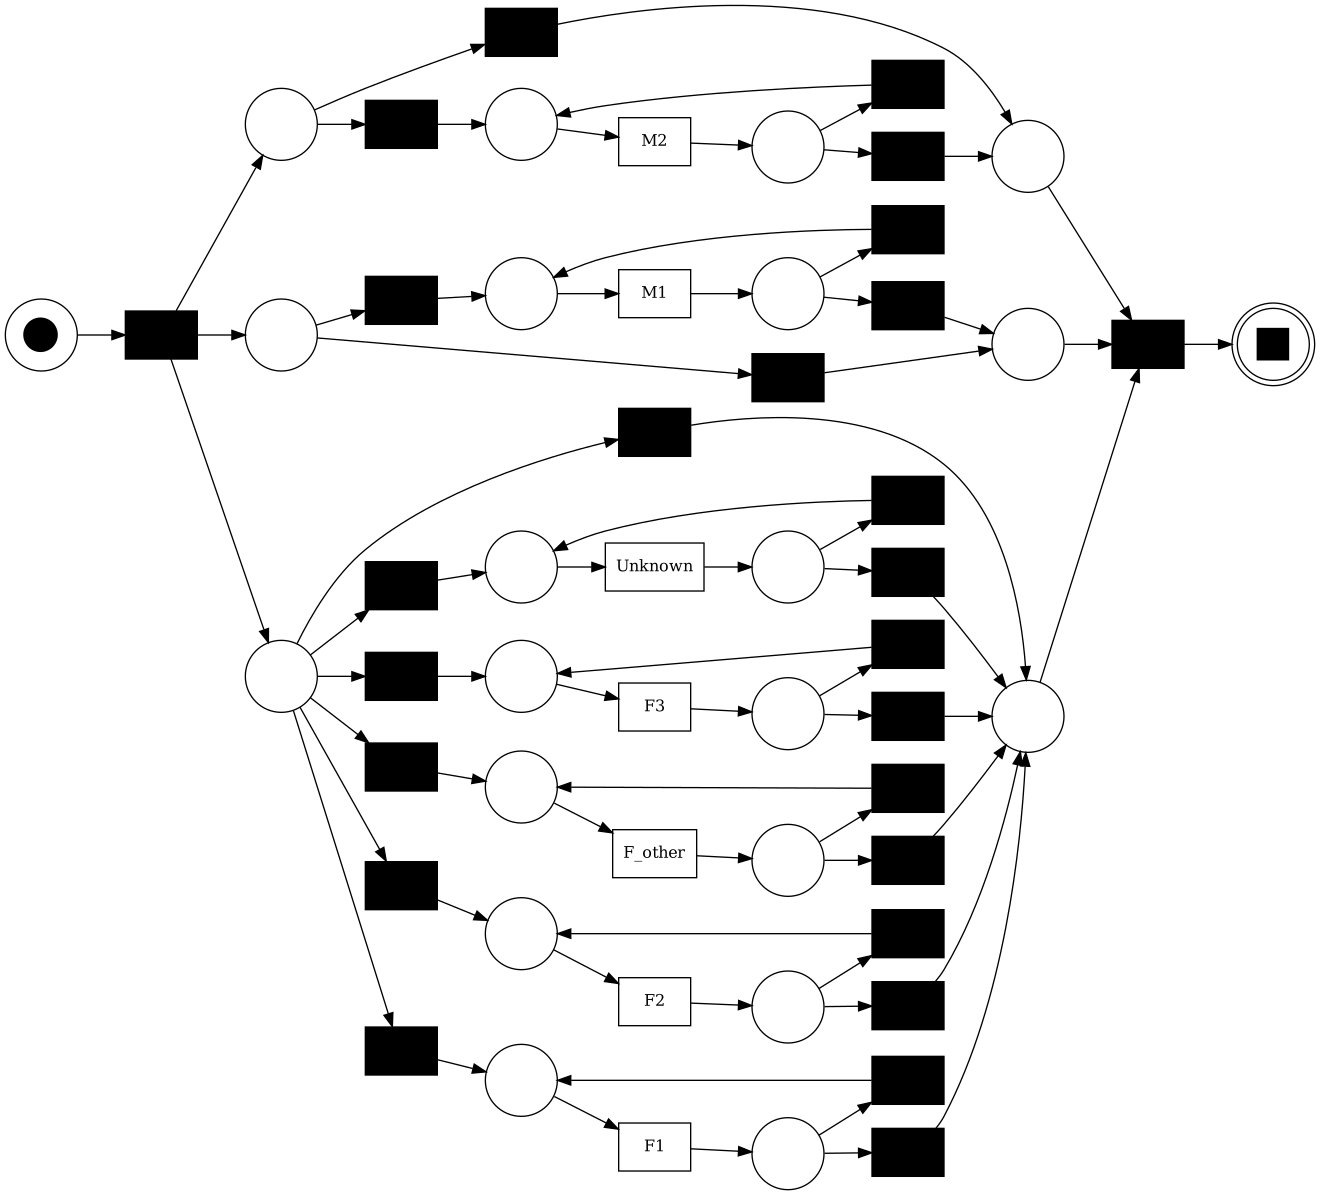

In [11]:
tree = pm4py.discover_process_tree_inductive(pm_log, noise_threshold=0.2)
net_i, im_i, fm_i = pm4py.convert_to_petri_net(tree)
pm4py.save_vis_petri_net(net_i, im_i, fm_i, str(FIG / "petri_IM_noise0.2.png"))
print("Дерево процесса IM 0.2:", tree)
show(FIG / "petri_IM_noise0.2.png")

### 4.4 Качество моделей

Как в экспериментах x2: люди делятся на train 80% / test 20% (seed 42), модели строятся на train, fitness и
precision (token-based replay) считаются на первых 2 000 людях train и test. Для HM 0.9 на журнале «по заключению»
дополнительно precision через выравнивания. Оба журнала оцениваются одинаково.

In [12]:
def discover(name, lg):
    kind, v = name.split("_")
    if kind == "HM":
        return pm4py.discover_petri_net_heuristics(lg, dependency_threshold=float(v))
    return pm4py.discover_petri_net_inductive(lg, noise_threshold=float(v))


rows = []
for variant, lg in LOGS.items():
    lg = pm4py.format_dataframe(lg[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                                case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
    train, test = S.split_people(lg)
    train_s, test_s = S.sample_cases(train, EVAL_CASES), S.sample_cases(test, EVAL_CASES)
    models = {m: discover(m, train) for m in MODELS}
    q = S.evaluate(models, train_s, test_s).assign(variant=variant)
    if ALIGN_CASES and variant == "по заключению":
        pa = pm4py.precision_alignments(S.sample_cases(test, ALIGN_CASES), *models["HM_0.9"])
        q.loc[(q["model"] == "HM_0.9") & (q["split"] == "test"), "precision_align"] = round(pa, 4)
    rows.append(q)
quality = pd.concat(rows, ignore_index=True)
quality.to_csv(OUT / "model_quality.csv", index=False)
quality[quality["split"] == "test"].set_index(["variant", "model"]).drop(columns=["split"])

cases  fitness_tbr  pct_fit_traces  precision_tbr  \
variant       model                                                        
по заключению HM_0.5    2000       0.9944           97.00         0.9515   
              HM_0.9    2000       0.9984           99.15         0.9367   
              HM_0.95   2000       0.9981           99.00         0.9273   
              IM_0.0    2000       1.0000          100.00         0.8748   
              IM_0.2    2000       0.9936           93.10         0.9617   
              IM_0.5    2000       0.9432           66.35         0.9617   
колонка Даши  HM_0.5    2000       1.0000          100.00         1.0000   
              HM_0.9    2000       1.0000          100.00         1.0000   
              HM_0.95   2000       1.0000          100.00         1.0000   
              IM_0.0    2000       1.0000          100.00         0.9482   
              IM_0.2    2000       0.9894           91.80         0.9405   
              IM_0.5    2000       0.9894           91.80         0.9405   

                           f1  places  transitions  silent  sec  \
variant       model                                               
по заключению HM_0.5   0.9725      17           51      44    0   
              HM_0.9   0.9666      16           54      47    0   
              HM_0.95  0.9614      14           50      44    0   
              IM_0.0   0.9332      33           44      37    1   
              IM_0.2   0.9774      22           33      26    0   
              IM_0.5   0.9523      22           32      25    0   
колонка Даши  HM_0.5   1.0000      16           28      21    0   
              HM_0.9   1.0000      16           28      21    0   
              HM_0.95  1.0000      16           28      21    0   
              IM_0.0   0.9734      19           32      25    0   
              IM_0.2   0.9643      19           31      24    0   
              IM_0.5   0.9643      19           31      24    0   

                       precision_align  
variant       model                     
по заключению HM_0.5               NaN  
              HM_0.9            0.9367  
              HM_0.95              NaN  
              IM_0.0               NaN  
              IM_0.2               NaN  
              IM_0.5               NaN  
колонка Даши  HM_0.5               NaN  
              HM_0.9               NaN  
              HM_0.95              NaN  
              IM_0.0               NaN  
              IM_0.2               NaN  
              IM_0.5               NaN

## Итоги

**Колонка Даши как состояние не годится.** Тяжесть в `c_charge_degree` меняется между заключениями только у 77 из
10 855 человек, поэтому все 7 668 переходов — петли X → X, в DFG 8 дуг, HM даёт fitness = precision = 1
и ничего не говорят о процессе. С тяжестью, найденной для каждого заключения, она совпадает только в 68% заключений.

**Тяжесть по заключению** (основной вариант): 7 состояний, 18 074 события у 10 406 человек, 42 дуги DFG.
- Петли X → X — 66% переходов: чаще всего человек снова попадает с обвинением той же тяжести
  (F1, F2, F3 — около 0.72, M1 — 0.51, M2 — 0.38).
- Самые заметные смены: M2 → F3 (0.31), M1 → F3 (0.26), M2 → M1 (0.18), F2 → F3 (0.12), F3 → M1 (0.11).
  То есть после мисдиминора человек нередко возвращается уже с фелонией 3-й степени.
- Медиана времени на свободе между заключениями — 132 дня (в варианте «категории × 2» — 124).

**Модели** (test, token-based replay):

| модель | fitness | precision |
|---|---|---|
| HM 0.5 | 0.994 | 0.952 |
| HM 0.9 | 0.998 | 0.937 (выравнивания 0.937) |
| HM 0.95 | 0.998 | 0.927 |
| IM 0.0 | 1.000 | 0.875 |
| IM 0.2 | 0.994 | 0.962 |
| IM 0.5 | 0.943 | 0.962 |

Precision здесь намного выше, чем в вариантах с типом преступления (0.54–0.83), но сравнивать напрямую нельзя:
состояний всего 7, у 60% людей одно заключение (трасса из одного события), а в таблице Даши только заключения
вокруг дела COMPAS (18 668 против 22 552 в таблице этапа 0). Дерево IM 0.2 — параллельные независимые петли
по каждой тяжести; оно почти ничего не говорит о порядке, хотя precision высокая. Для графа переходов
лучше смотреть HM 0.9 и матрицу переходов.

# Этапы 2–3 (п. 1.1 плана): параметры переходов и модели выживаемости

Кейс: данные Даши, состояние = тяжесть обвинения. Журнал и граф этапа 1 построены выше; здесь к ним добавляются

- **Этап 2.** Параметры переходов: вероятности $p_{ij}$ и распределения времени между заключениями.
- **Этап 3.** Признаки объекта (возраст, пол, раса, исходный балл COMPAS) и признаки события (тяжесть,
  число обвинений, длительность заключения, номер заключения, старое дело) и модели выживаемости между
  состояниями: CoxPH, дерево и случайный лес выживаемости; влияние признаков на переходы.

**Одна строка = одно заключение человека** (таблица `E`). Из каждого заключения $A$ человек выходит на свободу
и либо попадает в следующее заключение $B$ (переход $A \to B$), либо наблюдение кончается (цензура).

- **Время перехода** $T$ — время на свободе: от выхода из $A$ до входа в $B$, дни (пересечения заключений
  в данных → 0). Это время риска для конкурирующих рисков.
- **Тип следующего события** $K$ — состояние $B$. Пара $(T, K)$ — то, что моделируется в п. 1.2 плана.
- **Цензура.** Последнее заключение человека цензурировано: $T$ — от выхода до конца наблюдения
  (`obs_end`), терминального состояния END нет. Кто на конец наблюдения ещё в заключении, времени на свободе
  не имеет и в моделях выживаемости не участвует (`at_risk = False`), но учтён в долях цензуры.

Состояние заключения — тяжесть самого тяжёлого обвинения (F1, F2, F3, F_other, M1, M2, Unknown), как в журнале «по заключению» этапа 1. Тяжесть здесь и есть состояние, поэтому признак события «фелония» внутри одного состояния постоянен и в моделях по состояниям выпадает сам.

Общий код этапов 2–3 — `stage23.py` (тот же файл во всех кейсах). Результаты — в `out\stage23\`:
CSV-таблицы, `stage23_tables.xlsx` (все таблицы листами) и рисунки в `figures\`.

In [13]:
import stage23 as ST

OUT23 = OUT / "stage23"
FIG23 = OUT23 / "figures"
FIG23.mkdir(parents=True, exist_ok=True)
RUN_RSF = True              # случайный лес выживаемости (около минуты)
MIN_ARC_EVENTS = 50         # модели Кокса по дугам — только для дуг с таким числом переходов

people = ST.compas_people(DB)                       # балл COMPAS из compas.db (по person_id)
E = ST.episodes_dasha(log, ep, people, S.OBS_END)   # log — журнал «по заключению» (шаг 2)
E.to_csv(OUT23 / "episodes.csv", index=False)
ST.episodes_summary(E)

людей                               10406.000
заключений                          18074.000
состояний                               7.000
переходов (наблюдались)              7668.000
цензурировано (последние)           10406.000
  из них ещё в заключении             521.000
доля петель X→X                         0.662
медиана дней на свободе до след.      132.000
переходов за 0 дней                   458.000
нет балла COMPAS                       19.000
dtype: float64

**Как читать.** `переходов (наблюдались)` — пары соседних заключений; `цензурировано` — по одному последнему
заключению на человека; `переходов за 0 дней` — следующее заключение началось в день выхода или раньше
(пересечения в данных). `нет балла COMPAS` — у этих людей нет `decile_score`, в моделях этапа 3 они выпадают.

## Этап 2. Параметры переходов

### 2.1. Вероятности переходов

Вложенная цепь Маркова: $p_{ij} = n_{ij} / \sum_k n_{ik}$ — доля переходов в $j$ среди всех **наблюдавшихся**
переходов из $i$. Доля цензуры — доля заключений $i$, после которых следующего заключения не было до конца
наблюдения. $p_{ij}$ не учитывает, когда случился переход и сколько людей не дожило до него под наблюдением;
это делают кумулятивные функции инцидентности в 2.5.

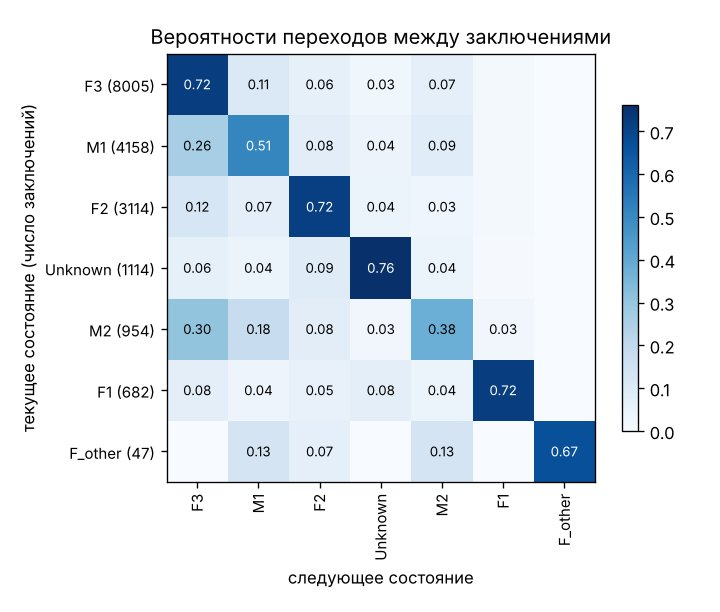

,заключений,переходов,доля цензуры,петля p(i→i)
F3,8005,3771,0.529,0.718
M1,4158,1344,0.677,0.510
F2,3114,1526,0.510,0.717
Unknown,1114,256,0.770,0.762
M2,954,479,0.498,0.380
F1,682,277,0.594,0.718
F_other,47,15,0.681,0.667


In [14]:
cnt, P, trans_summary = ST.transition_matrix(E)
cnt.to_csv(OUT23 / "transition_counts.csv")
P.round(4).to_csv(OUT23 / "transition_probs.csv")
trans_summary.to_csv(OUT23 / "transition_summary.csv")
ST.plot_matrix(P, FIG23 / "transition_matrix.png", "Вероятности переходов между заключениями",
               n=trans_summary["заключений"], annotate_min=0.02)
show(FIG23 / "transition_matrix.png")
trans_summary

**Как читать матрицу.** Строка — состояние текущего заключения (в скобках — число заключений), столбец —
следующего; в клетке $p_{ij}$ (подписаны $\ge 0.02$). Диагональ — повтор того же состояния (петля графа).
В таблице: сколько заключений в состоянии, сколько из них закончились переходом, доля цензуры и петля $p_{ii}$.

### 2.2. Время на свободе по дугам

Для каждой дуги $i \to j$ — описательная статистика времени на свободе среди тех, кто совершил этот переход
(дни): число переходов, $p_{ij}$, среднее, квартили, 90-й перцентиль. Показаны дуги с не менее 30 переходами.

In [15]:
arcs23 = ST.arc_times(E)
arcs23.to_csv(OUT23 / "arc_times.csv", index=False)
arcs23[arcs23["n"] >= 30].sort_values("n", ascending=False).head(25)

,from,to,n,p,mean,q25,median,q75,q90
14,F3,F3,2709,0.718,191.7,51.0,126.0,273.0,465.2
7,F2,F2,1094,0.717,182.1,27.0,113.5,269.8,465.7
26,M1,M1,686,0.510,216.2,61.0,151.0,325.8,507.5
15,F3,M1,403,0.107,226.4,68.5,154.0,349.5,508.8
24,M1,F3,352,0.262,229.7,62.8,151.0,320.8,572.7
16,F3,M2,265,0.070,181.3,38.0,116.0,261.0,457.4
13,F3,F2,243,0.064,177.8,52.5,114.0,247.5,412.6
0,F1,F1,199,0.718,200.0,0.0,110.0,297.0,569.4
41,Unknown,Unknown,195,0.762,161.5,30.5,93.0,236.5,439.2
8,F2,F3,187,0.123,199.4,47.5,130.0,294.0,483.2


### 2.3. Время до следующего заключения из каждого состояния (с цензурой)

Для состояния $i$ — время до следующего заключения любого типа. Цензурированные (последние) заключения
учитываются: кривая Каплана–Мейера $S(t)$ — доля тех, кто ещё не вернулся в заключение к дню $t$.
Подбираются параметрические распределения (экспоненциальное, Вейбулла, логнормальное, лог-логистическое),
лучшее — по минимальному AIC. Параметр формы Вейбулла $\rho < 1$ означает, что риск нового заключения
со временем на свободе падает (чаще всего возвращаются в первые месяцы).

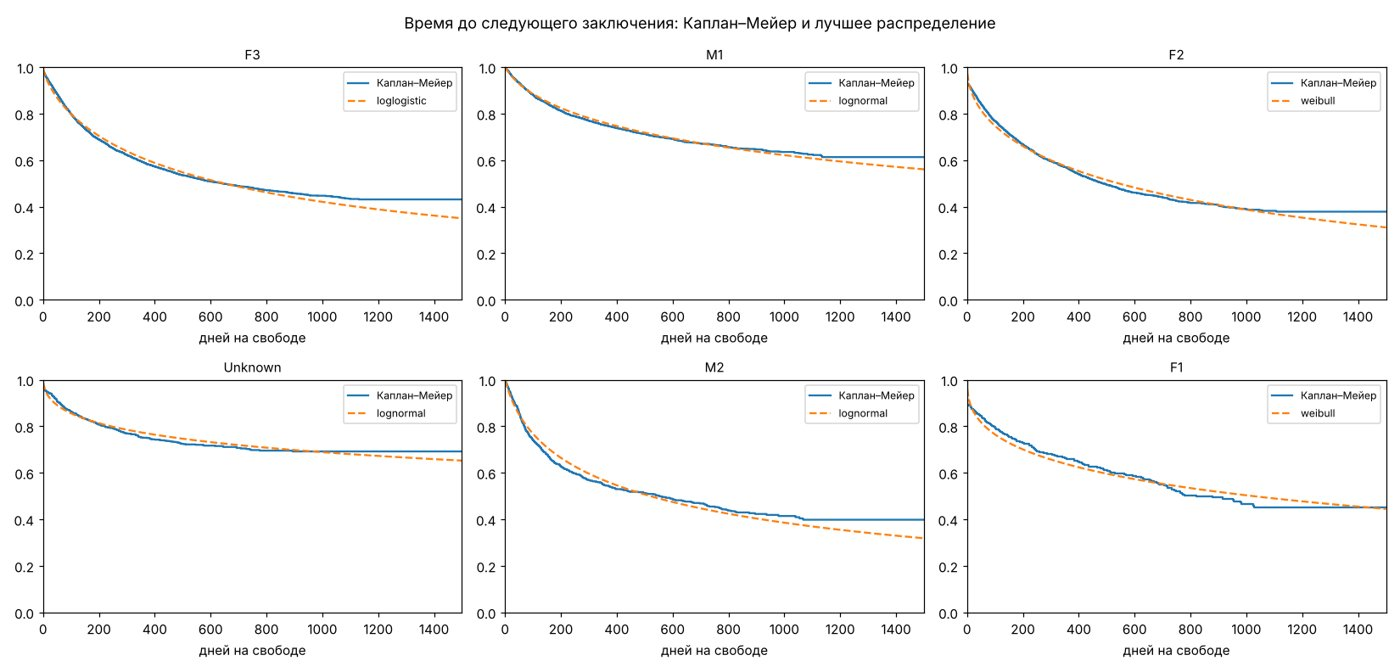

,n,events,km_median,S(365),S(730),weibull_rho,best,best_median
state,,,,,,,,
F3,7856,3771,643.0,0.588,0.485,0.615,loglogistic,649.0
M1,4148,1344,inf,0.748,0.670,0.630,lognormal,2228.1
F2,2934,1526,488.0,0.562,0.430,0.514,weibull,543.4
Unknown,991,256,inf,0.751,0.702,0.432,lognormal,7309.9
M2,951,479,551.0,0.545,0.457,0.612,lognormal,519.5
F1,628,277,820.0,0.659,0.533,0.409,weibull,1022.9


In [16]:
state_dist, state_fits = ST.fit_state_distributions(E)
state_dist.to_csv(OUT23 / "state_time_distributions.csv")
top_states = list(state_dist.index[:6])
ST.plot_state_fits(state_fits, FIG23 / "state_time_fits.png", top_states,
                   "Время до следующего заключения: Каплан–Мейер и лучшее распределение")
show(FIG23 / "state_time_fits.png")
state_dist[["n", "events", "km_median", "S(365)", "S(730)", "weibull_rho", "best", "best_median"]]

**Как читать.** `km_median` — медиана Каплана–Мейера (дни; `inf` — больше половины не вернулись до конца
наблюдения), `S(365)` и `S(730)` — доля не вернувшихся за 1 и 2 года, `weibull_rho` — форма Вейбулла,
`best` — распределение с минимальным AIC и его медиана. Значения AIC всех распределений — в CSV.

### 2.4. Полумарковская модель: распределение времени на дуге

В полумарковской модели процесс задаётся двумя частями: вероятностями $p_{ij}$ (2.1) и распределением
времени $F_{ij}(t)$ при условии, что произошёл именно переход $i \to j$. Для дуг с не менее 30 переходами
подбираются Вейбулл, логнормальное и лог-логистическое распределения (только наблюдавшиеся переходы, без
цензуры), лучшее — по AIC. Условные распределения на дугах обычно с $\rho \approx 1$: падающий риск
в 2.3 получается в основном из-за смеси людей, которые вернутся, и тех, кто не вернётся.

In [17]:
arc_dist = ST.fit_arc_distributions(E)
arc_dist.to_csv(OUT23 / "arc_time_distributions.csv", index=False)
print("лучшее распределение на дугах:", arc_dist["best"].value_counts().to_dict())
print("доля дуг с формой Вейбулла rho < 1:", round(float((arc_dist["weibull_rho"] < 1).mean()), 3))
arc_dist.head(20)

лучшее распределение на дугах: {'weibull': 20, 'lognormal': 2}
доля дуг с формой Вейбулла rho < 1: 0.773


,from,to,n,median_days,weibull_lambda,weibull_rho,best_median,best
0,F3,F3,2709,126.0,181.7,0.886,120.1,weibull
1,F2,F2,1094,113.5,143.1,0.646,81.1,weibull
2,M1,M1,686,151.0,218.5,1.027,152.9,weibull
3,F3,M1,403,154.0,228.6,1.026,159.9,weibull
4,M1,F3,352,151.0,223.5,0.940,151.4,weibull
5,F3,M2,265,116.0,174.3,0.920,117.1,weibull
6,F3,F2,243,114.0,176.5,0.983,121.6,weibull
7,F1,F1,199,110.0,121.9,0.498,58.4,weibull
8,Unknown,Unknown,195,93.0,128.2,0.664,73.8,weibull
9,F2,F3,187,130.0,179.0,0.797,113.0,weibull


### 2.5. Конкурирующие риски: вероятность перейти в $j$ за $t$ дней

Из состояния $i$ человек может попасть в любое из состояний $j$ — это конкурирующие риски; цензура —
конец наблюдения. Оценка Аалена–Йохансена даёт кумулятивную функцию инцидентности
$\mathrm{CIF}_{ij}(t) = P(T \le t,\ K = j \mid i)$ — вероятность, что следующим будет заключение типа $j$ и
случится не позже $t$. В отличие от $p_{ij}$, она учитывает время и цензуру; сумма по $j$ — вероятность
любого нового заключения за $t$ (линия «любое» $= 1 - S(t)$ из 2.3). Таблица — для состояний с не менее
200 заключениями на горизонтах 90, 180, 365, 730 дней.

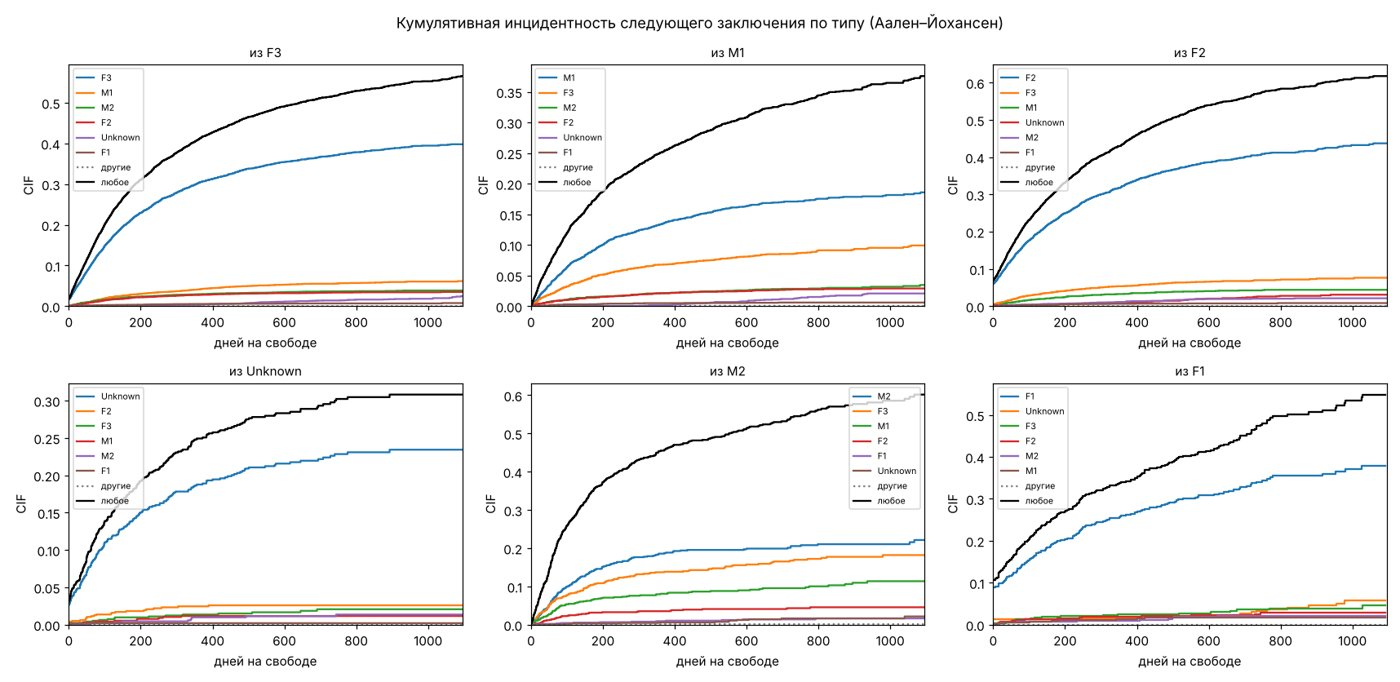

to,любое,F3,F2,M1,M2,Unknown,F1,F_other
from,,,,,,,,
F3,0.412,0.304,0.028,0.042,0.030,0.004,0.006,NaN
M1,0.252,0.068,0.021,0.134,0.021,0.002,0.005,0.000
F2,0.438,0.054,0.325,0.033,0.011,0.009,0.006,NaN
Unknown,0.249,0.014,0.024,0.012,0.010,0.188,0.002,NaN
M2,0.455,0.137,0.035,0.081,0.186,0.006,0.009,0.001
F1,0.341,0.025,0.018,0.013,0.010,0.014,0.260,NaN


In [18]:
cif, cif_curves = ST.cumulative_incidence(E)
cif.to_csv(OUT23 / "cif_competing_risks.csv", index=False)
cif_states = list(cif_curves)[:6]
ST.plot_cif(cif_curves, FIG23 / "cif_top_states.png", cif_states,
            "Кумулятивная инцидентность следующего заключения по типу (Аален–Йохансен)")
show(FIG23 / "cif_top_states.png")
# вероятность за 1 год: строки — откуда, столбцы — куда (самые частые направления)
cif_1y = cif.pivot(index="from", columns="to", values="CIF_365d")
cols = ["любое"] + [c for c in cif[cif["to"] != "любое"].groupby("to")["events"].sum().sort_values(ascending=False).index[:8]]
cif_1y.reindex(index=[s for s in ST.state_order(E) if s in cif_1y.index], columns=cols).round(3)

## Этап 3. Признаки объекта и события, модели выживаемости между состояниями

Признаки (в моделях берутся строки с известным временем на свободе и баллом COMPAS):

| признак | что это | тип |
|---|---|---|
| `age10` | возраст на дату оценки COMPAS, на 10 лет (HR — на каждые 10 лет) | объект |
| `male` | мужчина | объект |
| `race_afam`, `race_other` | афроамериканец; другая раса (Hispanic, Asian, Native American, Other); база — Caucasian | объект |
| `score` | исходный балл COMPAS `decile_score` (1–10, риск рецидива) | объект |
| `felony` | самое тяжёлое обвинение заключения — фелония | событие |
| `n_charges` | число обвинений в заключении (до 10) | событие |
| `log_dur` | $\log(1 + \text{дней в заключении})$ | событие |
| `prior_eps` | сколько заключений было у человека раньше (до 5) | событие |
| `old_case` | в заключении есть обвинение по делу из прежнего заключения (нет у данных Даши) | событие |

Признаки объекта не меняются во времени. Балл COMPAS и возраст взяты на дату оценки COMPAS, которая для
части заключений позже их начала, — это свойство данных ProPublica (одна оценка на человека).
Люди делятся на train 80% / test 20% (seed 42), C-index (согласованность прогноза риска и времени;
0.5 — случайно, 1 — идеально) считается на test.

In [19]:
feats = ST.features_of(E)
R = ST.model_frame(E, feats)
train23, test23 = ST.split_people(R)
print("признаки:", feats)
print(f"строк для моделей: {len(R):,} (train {len(train23):,}, test {len(test23):,}); "
      f"событий в train: {int(train23['event'].sum()):,}")
R[feats].describe().T[["mean", "std", "min", "max"]].round(3)

признаки: ['age10', 'male', 'race_afam', 'race_other', 'score', 'felony', 'n_charges', 'log_dur', 'prior_eps']
строк для моделей: 17,535 (train 14,021, test 3,514); событий в train: 6,132


,mean,std,min,max
age10,3.382,1.156,1.8,9.600
male,0.817,0.386,0.0,1.000
race_afam,0.537,0.499,0.0,1.000
race_other,0.131,0.337,0.0,1.000
score,5.011,2.929,1.0,10.000
felony,0.653,0.476,0.0,1.000
n_charges,4.349,3.624,0.0,10.000
log_dur,2.049,1.681,0.0,8.225
prior_eps,0.723,1.104,0.0,5.000


### 3.1. CoxPH: время до следующего заключения любого типа

Модель пропорциональных рисков Кокса, **стратифицированная по текущему состоянию**: у каждого состояния свой
базовый риск $h_{0,i}(t)$, а признаки действуют одинаково, $h(t \mid i, x) = h_{0,i}(t)\, e^{\beta^\top x}$.
$\mathrm{HR} = e^\beta$ — во сколько раз признак меняет риск нового заключения (HR > 1 — возвращаются
быстрее). Ниже — сравнение C-index на test для моделей «только состояние», «только признаки»,
«состояние + признаки» (состояние — индикаторами, база — первое по алфавиту; состояния реже 30 заключений
в train остаются в базе) и HR состояний из последней модели.

In [20]:
cph, cox_hr, cox_cindex, cox_state_hr = ST.cox_any(train23, test23, feats)
cox_hr.to_csv(OUT23 / "cox_any_hr.csv")
cox_cindex.to_csv(OUT23 / "cox_cindex_test.csv", header=["c_index"])
cox_state_hr.to_csv(OUT23 / "cox_state_hr.csv")
print("C-index на test:")
print(cox_cindex.to_string())
cox_hr

C-index на test:
только состояние        0.5750
только признаки         0.6756
состояние + признаки    0.6787


,признак,HR,HR 95% низ,HR 95% верх,p
covariate,,,,,
age10,возраст (на 10 лет),0.973,0.950,0.997,0.0306
male,мужчина,1.261,1.176,1.352,0.0000
race_afam,афроамериканец,1.014,0.958,1.075,0.6257
race_other,др. раса (не белый),0.855,0.781,0.937,0.0008
score,балл COMPAS (decile),1.159,1.148,1.171,0.0000
n_charges,число обвинений,1.015,1.008,1.023,0.0001
log_dur,log длит. заключения,1.002,0.985,1.018,0.8397
prior_eps,заключений до этого,1.145,1.119,1.172,0.0000


In [21]:
# HR текущего состояния (модель «состояние + признаки»; база — первое по алфавиту состояние)
cox_state_hr.sort_values("HR")

,HR,p
F_other,0.7528,0.3465
Unknown,0.7581,0.0416
M1,0.8893,0.3390
F2,1.1419,0.0372
F3,1.1494,0.0215
M2,1.3372,0.0261


### 3.2. Модели Кокса по дугам (причинно-специфичные риски)

Влияние признаков на **конкретный переход** $i \to j$: для людей в состоянии $i$ событие — следующее
заключение типа $j$, переходы в другие типы и конец наблюдения — цензура. Такая модель
причинно-специфичного риска $h_{ij}(t \mid x) = h_{0,ij}(t)\, e^{\beta_{ij}^\top x}$ — стандартный способ
оценивать признаки при конкурирующих рисках. Модели строятся на всех людях для дуг с не менее
`MIN_ARC_EVENTS` переходами (лёгкая L2-регуляризация, penalizer = 0.05, иначе на редких дугах коэффициенты
расходятся). Признак, постоянный внутри состояния, выпадает.

In [22]:
arc_cox = ST.cox_arcs(R, feats, min_events=MIN_ARC_EVENTS)
arc_cox.to_csv(OUT23 / "cox_arcs_hr.csv", index=False)
arc_effects = ST.arc_effects_summary(arc_cox, feats)
arc_effects.to_csv(OUT23 / "cox_arcs_feature_summary.csv")
print(f"дуг с моделью: {arc_cox['arc'].nunique()}")
arc_effects

дуг с моделью: 20


,дуг,HR>1 значимо,HR<1 значимо,медиана HR,мин HR,макс HR
возраст (на 10 лет),20,0,5,0.938,0.882,1.127
мужчина,20,6,0,1.237,0.935,1.411
афроамериканец,20,2,1,1.112,0.883,1.273
др. раса (не белый),20,1,3,0.913,0.510,1.516
балл COMPAS (decile),20,18,0,1.088,1.042,1.142
число обвинений,20,3,0,1.006,0.703,1.044
log длит. заключения,20,3,1,1.014,0.935,1.146
заключений до этого,20,9,0,1.099,0.934,1.379


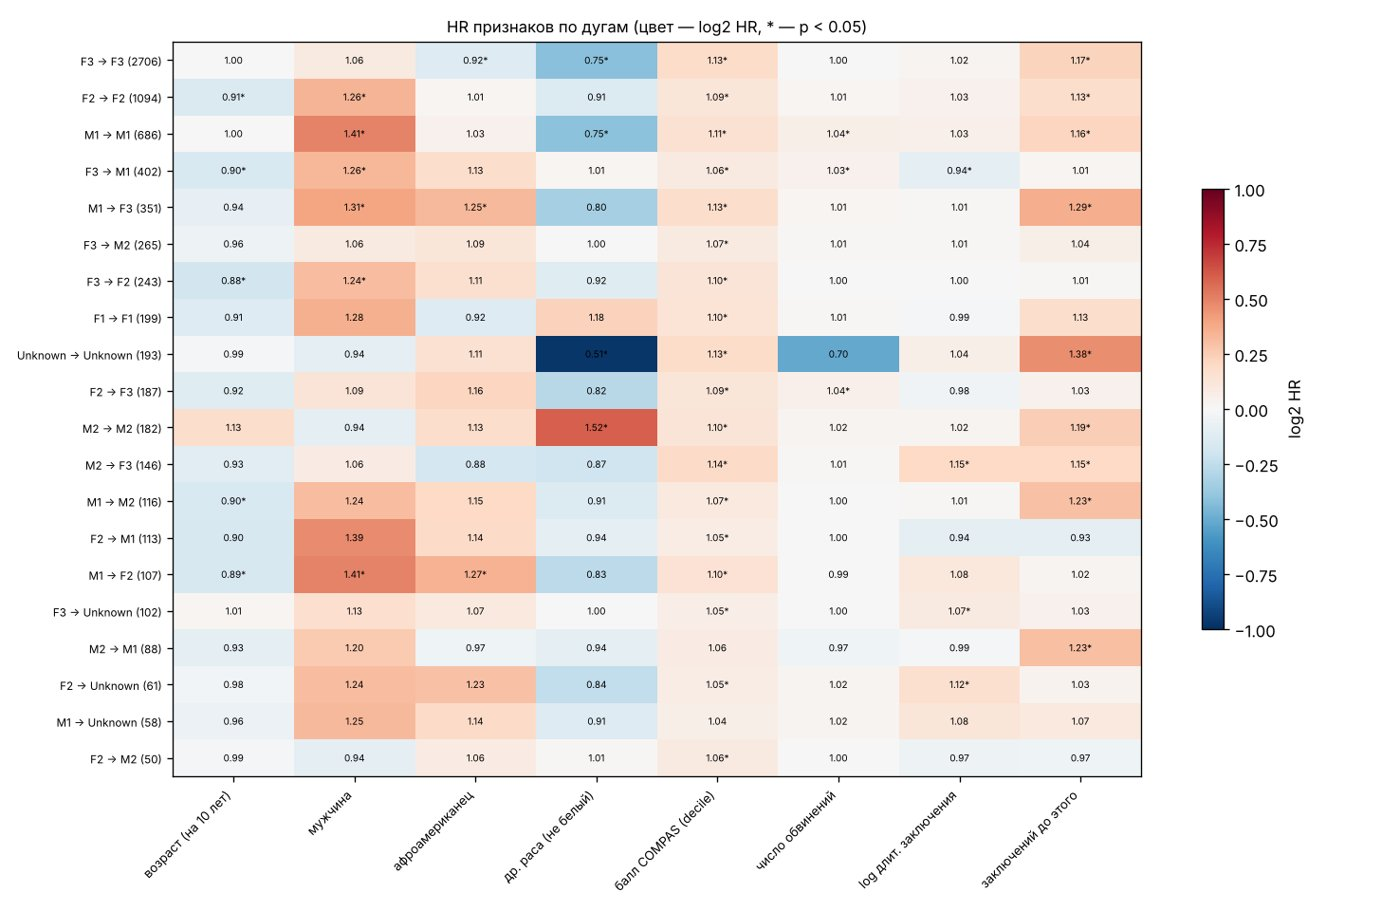

In [23]:
ST.plot_arc_heatmap(arc_cox, feats, FIG23 / "cox_arcs_heatmap.png",
                    "HR признаков по дугам (цвет — log2 HR, * — p < 0.05)")
show(FIG23 / "cox_arcs_heatmap.png")

**Как читать.** Таблица: на скольких дугах признак значимо (p < 0.05) ускоряет (HR > 1) или замедляет
(HR < 1) переход, медиана и размах HR. Тепловая карта — самые частые дуги (в скобках число переходов):
красное — признак ускоряет именно этот переход, синее — замедляет. Признак, который ускоряет одни переходы
и замедляет другие, меняет не только «скорость возвращения», но и **тип** следующего заключения.
Все HR и доверительные интервалы — в `cox_arcs_hr.csv`.

### 3.3. Дерево выживаемости

Дерево выживаемости (scikit-survival, разбиения по log-rank) для времени до следующего заключения: признаки
+ текущее состояние. Глубина 3, в листе не меньше 300 заключений, чтобы дерево читалось. Листья
отсортированы от самого быстрого возвращения: `km_median` — медиана Каплана–Мейера в листе, `S365` — доля
не вернувшихся за год. Ниже — кривые Каплана–Мейера листьев.

C-index дерева на test: 0.6555


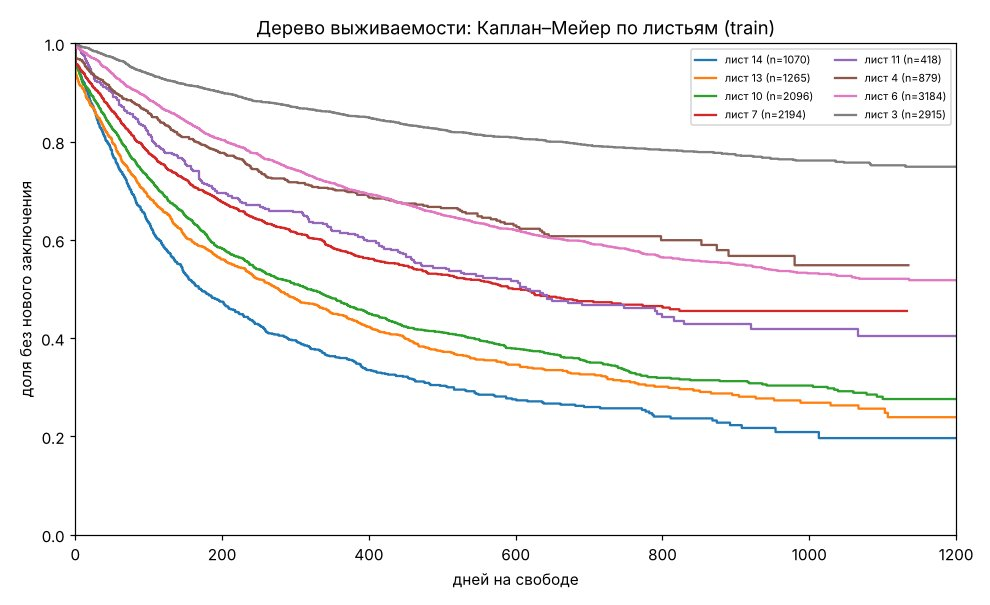

,leaf,path,n,events,km_median,S365
0,14,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,1070,724,171.0,0.360
1,13,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,1265,775,277.0,0.446
2,10,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,2096,1237,317.0,0.472
3,7,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,2194,924,607.0,0.577
4,11,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,418,206,619.0,0.615
5,4,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,879,276,inf,0.701
6,6,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,3184,1356,inf,0.707
7,3,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,2915,634,inf,0.855


In [24]:
tree23, leaves23, tree_c = ST.survival_tree(train23, test23, feats)
leaves23.to_csv(OUT23 / "survival_tree_leaves.csv", index=False)
print(f"C-index дерева на test: {tree_c:.4f}")
ST.plot_tree_leaves(train23, tree23, feats, leaves23, FIG23 / "survival_tree_leaves.png",
                    "Дерево выживаемости: Каплан–Мейер по листьям (train)")
show(FIG23 / "survival_tree_leaves.png")
leaves23

### 3.4. Случайный лес выживаемости и важность признаков

Random Survival Forest (100 деревьев, лист от 50 заключений) — нелинейная модель для сравнения с Коксом.
Важность признака — насколько падает C-index на test, если перемешать этот признак (текущее состояние
перемешивается целиком). Флаг `RUN_RSF = False` пропускает этот шаг.

In [25]:
if RUN_RSF:
    rsf_c, rsf_imp, rsf_sec = ST.random_forest(train23, test23, feats)
    rsf_imp.to_csv(OUT23 / "rsf_permutation_importance.csv", header=["drop_in_c_index"])
    print(f"RSF: C-index на test {rsf_c:.4f} ({rsf_sec} с)")
    display(rsf_imp.to_frame("падение C-index"))
else:
    rsf_c, rsf_imp = float("nan"), pd.Series(dtype=float)

cindex_all = pd.concat([cox_cindex.rename(lambda s: "Кокс: " + s),
                        pd.Series({"дерево выживаемости": round(tree_c, 4), "случайный лес": round(rsf_c, 4)})])
cindex_all.to_csv(OUT23 / "cindex_all_models.csv", header=["c_index"])
ST.save_excel(OUT23 / "stage23_tables.xlsx", {
    "сводка": ST.episodes_summary(E).to_frame("значение"), "переходы_число": cnt, "переходы_p": P.round(4),
    "переходы_сводка": trans_summary, "время_дуги": arcs23, "время_состояния": state_dist,
    "распр_дуги": arc_dist, "CIF": cif, "cox_hr": cox_hr, "cox_состояния": cox_state_hr,
    "cox_дуги": arc_cox, "cox_дуги_сводка": arc_effects, "дерево_листья": leaves23,
    "rsf_важность": rsf_imp.to_frame("падение C-index"), "c_index": cindex_all.to_frame("c_index")})
cindex_all.to_frame("C-index (test)")

RSF: C-index на test 0.6777 (4 с)


,падение C-index
балл COMPAS (decile),0.0880
заключений до этого,0.0268
log длит. заключения,0.0073
текущее состояние,0.0038
возраст (на 10 лет),0.0025
мужчина,0.0025
фелония,0.0014
число обвинений,0.0014
афроамериканец,0.0010
др. раса (не белый),0.0002


таблицы: /tmp/claude-0/w/jl/stage1/dasha_severity/out/stage23/stage23_tables.xlsx


,C-index (test)
Кокс: только состояние,0.5750
Кокс: только признаки,0.6756
Кокс: состояние + признаки,0.6787
дерево выживаемости,0.6555
случайный лес,0.6777


## Итоги этапов 2–3 (данные Даши, тяжесть)

**Этап 2. Параметры переходов.** 18 074 заключения 10 406 человек, 7 состояний, 7 668 переходов.
- Вероятности: петли 0.72 у F1, F2, F3 и 0.51 у M1; после мисдиминора часто возвращаются с F3
  (M2 → F3 0.31, M1 → F3 0.26).
- Время: возвращаются медленнее, чем в таблице этапа 0 (в окне вокруг дела COMPAS): за год после F3 41%,
  после F2 44%, после M2 46%, после M1 только 25% (CIF «любое»). Форма Вейбулла ρ = 0.41–0.63 —
  риск падает со временем сильнее, чем в вариантах с типами. На дугах условное время с медианой
  110–155 дней, Вейбулл.

**Этап 3. Признаки.** Тяжесть здесь — само состояние, поэтому «фелония» в модели по состояниям не оценивается.
Кокс, стратифицированный по тяжести: балл COMPAS 1.159, предыдущее заключение 1.145, мужчина 1.26,
другая раса 0.86, возраст 0.97 на 10 лет, число обвинений 1.015 на каждое; остальные незначимы.
- HR тяжести (база F1): M2 1.34, F3 1.15, F2 1.14 — после самых лёгких и средних обвинений возвращаются быстрее;
  M1 и Unknown — медленнее.
- C-index на test: только состояние 0.575, только признаки 0.676, вместе 0.679, дерево 0.656, лес 0.678.
- По 20 дугам: балл ускоряет 18 переходов, мужской пол — 6 (сильнее всего переходы из M1), возраст замедляет 5.
- Дерево: балл COMPAS, затем состояние F3 (быстрее) или M1 (медленнее) и число прошлых заключений.

**Сравнение кейсов** (C-index на test; Кокс «состояние + признаки» / только состояние / случайный лес):
эксп. 1 — 0.674 / 0.576 / 0.678; эксп. 3 — 0.675 / 0.577 / 0.678; данные Даши — 0.679 / 0.575 / 0.678;
15 категорий all_new — 0.674 / 0.572 / 0.677; oldcase — 0.675 / 0.578 / 0.678. Во всех кейсах картина одна:
скорость возвращения определяют в основном признаки человека, а тип текущего заключения добавляет немного;
зато тип влияет на то, **куда** человек перейдёт (матрица переходов, CIF и модели по дугам).

**Ограничения.** Балл COMPAS и возраст взяты на дату оценки COMPAS (одна на человека), для части заключений она
позже их начала. HR в моделях по дугам — без поправки на множественные сравнения (много дуг × 10 признаков),
поэтому одиночные значимые HR на редких дугах — ориентиры, а не выводы. Пропорциональность рисков не
проверялась формально; дерево и лес её не требуют и дают близкий C-index.
